В этом ноутбуке посмотрю, что получилось после генерации датасета: сколько в нём изменений, как распределены метки и подходит ли разбиение для обучения.

Одна строка в `pairs.csv` описывает пару `(изменение кода, потребитель)`. Код сервисов и Git diff лежат отдельно, пути к ним записаны в таблице. Контрактные тесты и результаты разметки находятся в `data/audit/`.

Ячейки можно выполнять по порядку из корня проекта или папки `notebooks/`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data/processed/pairs.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/processed/pairs.csv").exists(), "Открой ноутбук из корня или из notebooks/"

pairs = pd.read_csv(ROOT / "data/processed/pairs.csv")
scenarios = pd.read_csv(ROOT / "data/processed/scenarios.csv")
edges = pd.read_csv(ROOT / "data/processed/dependency_edges.csv")
audit = json.loads((ROOT / "data/audit/validation_results.json").read_text(encoding="utf-8"))
print(
    f"Пар: {len(pairs)}, уникальных изменений: {pairs.scenario_id.nunique()}, семейств: {pairs.family_id.nunique()}"
)
display(pairs.head())

Пар: 405, уникальных изменений: 81, семейств: 27


,pair_id,scenario_id,family_id,split,provider,consumer,change_type,diff_path,provider_old_path,provider_new_path,consumer_code_path,num_files_changed,lines_added,lines_deleted,diff_chars,consumer_code_chars,api_schema_unchanged,label
0,pair_0001,price_tax_inclusion_v01,price_tax_inclusion,train,PricingService,CustomerPortalService,value_semantics,data/raw/scenarios/price_tax_inclusion_v01/cha...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/con...,1,1,1,303,151,1,1
1,pair_0002,price_tax_inclusion_v01,price_tax_inclusion,train,PricingService,SalesAnalyticsService,value_semantics,data/raw/scenarios/price_tax_inclusion_v01/cha...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/con...,1,1,1,303,165,1,1
2,pair_0003,price_tax_inclusion_v01,price_tax_inclusion,train,PricingService,ReceiptService,value_semantics,data/raw/scenarios/price_tax_inclusion_v01/cha...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/con...,1,1,1,303,151,1,0
3,pair_0004,price_tax_inclusion_v01,price_tax_inclusion,train,PricingService,FinanceService,value_semantics,data/raw/scenarios/price_tax_inclusion_v01/cha...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/con...,1,1,1,303,140,1,0
4,pair_0005,price_tax_inclusion_v01,price_tax_inclusion,train,PricingService,CheckoutService,value_semantics,data/raw/scenarios/price_tax_inclusion_v01/cha...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/pro...,data/raw/scenarios/price_tax_inclusion_v01/con...,1,1,1,303,191,1,1


## Объём и качество

Сначала проверю пропуски, повторяющиеся пары и пути к исходникам. Результаты контрактных проверок прочитаю из сохранённого отчёта `data/audit/validation_results.json`.


In [2]:
print("Пропуски по колонкам:")
print(pairs.isna().sum().to_string())
print("Дубликаты по (scenario_id, consumer):", pairs.duplicated(["scenario_id", "consumer"]).sum())
print(
    "Отсутствующие пути:",
    sum(
        not (ROOT / p).is_file()
        for col in ["diff_path", "provider_old_path", "provider_new_path", "consumer_code_path"]
        for p in pairs[col]
    ),
)
print("Контракты воспроизведены:", audit["replayed_consumer_contracts"])
print("Изменения схемы API:", audit["api_schema_violations"])
assert audit["status"] == "PASS"

Пропуски по колонкам:
pair_id                 0
scenario_id             0
family_id               0
split                   0
provider                0
consumer                0
change_type             0
diff_path               0
provider_old_path       0
provider_new_path       0
consumer_code_path      0
num_files_changed       0
lines_added             0
lines_deleted           0
diff_chars              0
consumer_code_chars     0
api_schema_unchanged    0
label                   0
Дубликаты по (scenario_id, consumer): 0
Отсутствующие пути: 0
Контракты воспроизведены: 405
Изменения схемы API: 0


Пропусков и повторяющихся пар нет, все пути к исходникам существуют. В сохранённом отчёте проверены 405 пар, расхождений API-схемы на тестовых входах нет. Здесь я читаю готовые результаты, заново контракты эта ячейка не запускает.


## Баланс меток

Посмотрю, сколько пар относится к каждому классу. Метка `1` означает, что новый provider нарушил хотя бы одну проверку потребителя. При `0` обе версии прошли имеющиеся проверки.


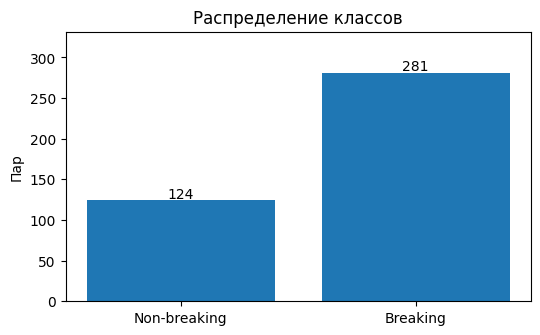

Доля breaking: 0.694


In [3]:
counts = pairs.label.value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Non-breaking", "Breaking"], counts.to_numpy())
for i, val in enumerate(counts):
    ax.text(i, val + 3, str(val), ha="center")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Пар")
ax.set_title("Распределение классов")
plt.show()
print("Доля breaking:", round(pairs.label.mean(), 3))

Breaking-пар больше: 281 против 124, то есть около 69%. Если всегда предсказывать breaking, accuracy уже будет около 69%, хотя все безопасные пары будут определены неверно. Поэтому при сравнении моделей буду смотреть Recall с ограничением на FPR.


## Типы изменений

Проверю, какие изменения встречаются чаще и как отличаются доли breaking между типами.


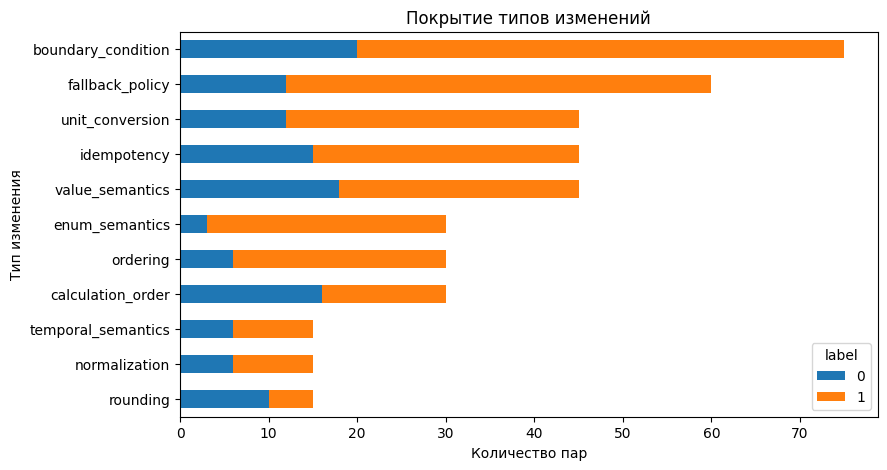

,count,mean
change_type,,
boundary_condition,75,0.733333
fallback_policy,60,0.800000
idempotency,45,0.666667
unit_conversion,45,0.733333
value_semantics,45,0.600000
enum_semantics,30,0.900000
calculation_order,30,0.466667
ordering,30,0.800000
normalization,15,0.600000


In [4]:
by_type = pd.crosstab(pairs.change_type, pairs.label).reindex(columns=[0, 1], fill_value=0)
by_type.sort_values(1).plot(kind="barh", stacked=True, figsize=(9, 5))
plt.xlabel("Количество пар")
plt.ylabel("Тип изменения")
plt.title("Покрытие типов изменений")
plt.show()
display(
    pairs.groupby("change_type").label.agg(["count", "mean"]).sort_values("count", ascending=False)
)

Доли breaking заметно отличаются: у `enum_semantics` это 27 из 30 пар, у `rounding` только 5 из 15. Значит, тип изменения может стать простой подсказкой для модели. При разборе ошибок стоит смотреть результаты по типам отдельно.


## Размер Git diff и влияние на сервисы

Один diff повторяется для пяти потребителей. Для графика оставлю одну точку на `scenario_id`, иначе одно изменение будет учтено пять раз. По вертикали покажу долю потребителей, у которых нарушился контракт.


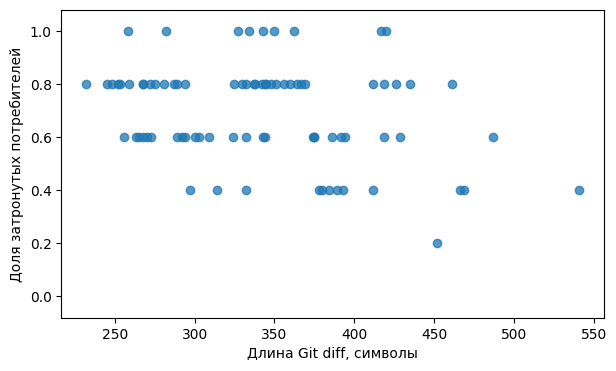

,scenario_id,diff_chars,breaking_consumers,fraction_affected,provider
count,81,81.000000,81.000000,81.000000,81
unique,81,NaN,NaN,NaN,9
top,backorder_policy_v01,NaN,NaN,NaN,InventoryService
freq,1,NaN,NaN,NaN,9
mean,NaN,342.469136,3.469136,0.693827,NaN
std,NaN,65.661078,0.923125,0.184625,NaN
min,NaN,232.000000,1.000000,0.200000,NaN
25%,NaN,289.000000,3.000000,0.600000,NaN
50%,NaN,342.000000,4.000000,0.800000,NaN
75%,NaN,384.000000,4.000000,0.800000,NaN


In [5]:
impact = (
    pairs.groupby("scenario_id")
    .agg(
        diff_chars=("diff_chars", "first"),
        breaking_consumers=("label", "sum"),
        fraction_affected=("label", "mean"),
        provider=("provider", "first"),
    )
    .reset_index()
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(impact.diff_chars, impact.fraction_affected, alpha=0.75)
ax.set_xlabel("Длина Git diff, символы")
ax.set_ylabel("Доля затронутых потребителей")
ax.set_ylim(-0.08, 1.08)
plt.show()
display(impact.describe(include="all"))

Изменения небольшие: от 232 до 541 символа. При этом число затронутых потребителей меняется от одного до пяти. По одному размеру diff нельзя понять, как каждый потребитель использует изменённый результат. Это буду проверять по его коду.


## Зависимости между сервисами

Посмотрю, сколько пар приходится на каждую связь provider и consumer. Это таблица покрытия датасета: сами зависимости заданы при генерации.


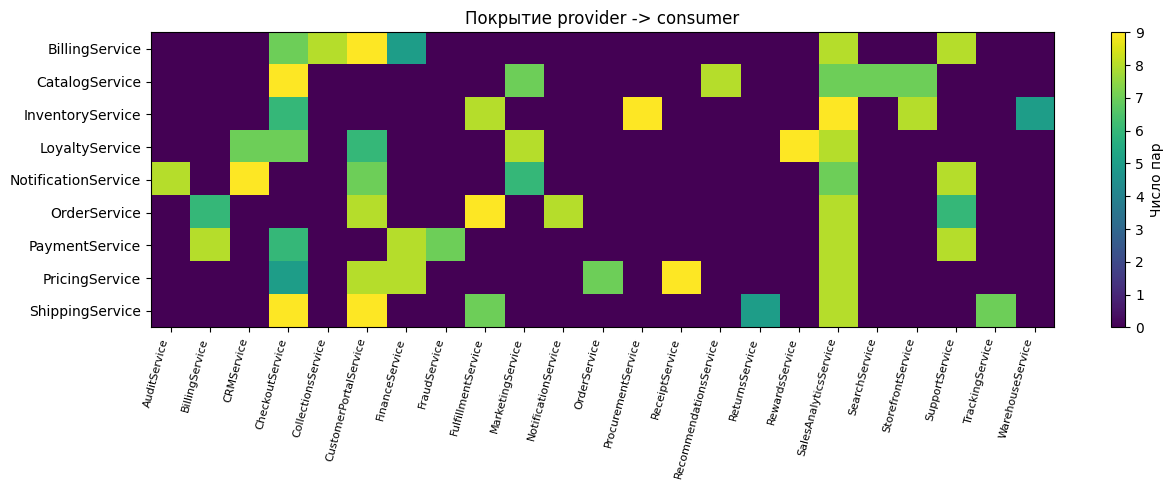

Рёбер графа зависимостей: 54


In [ ]:
matrix = pd.crosstab(pairs.provider, pairs.consumer)
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(matrix.to_numpy(), aspect="auto")
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(matrix.index)), matrix.index)
plt.colorbar(im, ax=ax, label="Число пар")
plt.title("Покрытие provider -> consumer")
plt.tight_layout()
plt.show()
print("Рёбер графа зависимостей:", len(edges))

## Разбиение по семействам

Варианты одного изменения похожи по смыслу, даже если код записан по-разному. Поэтому оставлю их в одной выборке. Проверю, что `family_id` и `scenario_id` не пересекаются между train, validation и test.


label        0    1
split              
test        23   37
train       85  200
validation  16   44


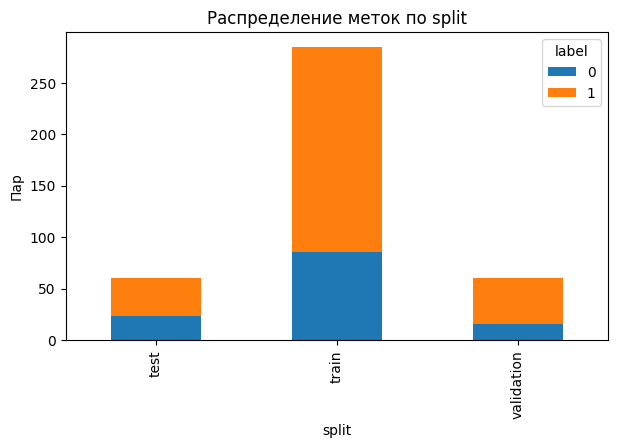

Семейств в разбиениях:
split
test           4
train         19
validation     4
Name: family_id, dtype: int64


In [ ]:
assert pairs.groupby("family_id").split.nunique().max() == 1
assert pairs.groupby("scenario_id").split.nunique().max() == 1
by_split = pd.crosstab(pairs.split, pairs.label)
print(by_split)
by_split.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.ylabel("Пар")
plt.title("Распределение меток по split")
plt.show()
print("Семейств в разбиениях:")
print(pairs.groupby("split").family_id.nunique())

В train получилось 19 семейств, в validation и test по четыре. Пересечений нет, но независимых тестовых сценариев мало. В validation всего 16 отрицательных пар: одна ложная тревога меняет FPR на 6,25 процентного пункта. Подбирать по такой выборке точный порог будет сложно.


## Разбор одной пары

Посмотрю на первый breaking-пример: прочитаю diff и код потребителя, чтобы понять, что именно изменилось и почему это для него важно.


In [ ]:
sample = pairs[pairs.label == 1].iloc[0]
print("Изменение:", sample.scenario_id)
print("Потребитель:", sample.consumer)
print("Метка:", sample.label)
print()
print("Git diff:")
print((ROOT / sample.diff_path).read_text(encoding="utf-8"))
print()
print("Код consumer:")
print((ROOT / sample.consumer_code_path).read_text(encoding="utf-8"))

Изменение: price_tax_inclusion_v01
Потребитель: CustomerPortalService
Метка: 1

Git diff:
--- a/pricingservice.py
+++ b/pricingservice.py
@@ -1,3 +1,3 @@
 def quote(request: dict) -> dict:
-    result = round(float(request["subtotal"]), 2)
+    result = round(float(request["subtotal"]) * (1 + float(request["vat_rate"])), 2)
     return {'total': result, "request_id": request["request_id"]}


Код consumer:
def process(provider, request: dict) -> dict:
    response = provider.quote(request)
    return {"report_bucket": int(float(response['total']) // 20)}



Здесь `total` начинает включать налог. `CustomerPortalService` делит сумму на 20 и берёт целую часть. Например, при сумме 100 и налоге 20% значение `total` меняется со 100 на 120, а категория с 5 на 6. Структура ответа та же, но результат работы потребителя уже другой.


## Что дальше

Для первого эксперимента данных достаточно: есть оба класса, разные типы изменений и разбиение по семействам. Начну с baseline на тексте diff и ID потребителя. Затем сравню его с моделью, которая получает код потребителя и семантические признаки от LLM.

Главное ограничение пока в самих данных. Код и тесты синтетические, а метки получены сравнением с результатами старой версии. Они показывают нарушение выбранных проверок, но не обязательно реального бизнес-контракта. Особенно это касается `label=0`: три успешных случая не гарантируют совместимость на всех входах.

Реальных PR и сетевого взаимодействия здесь нет. Результаты на этом наборе позволят сравнить подходы внутри учебного проекта. Для проверки на реальных сервисах понадобятся другие данные.
